### Ερώτημα 1
Υπολογισμός του Motion Energy Image (MEI) για κάθε gesture.

In [ ]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import re

#for sorting the folders
def get_sequence_number(path):
    match = re.search(r"\d+", path.name)
    return int(match.group()) if match else float("inf")

def compute_mei(sequence_folder, threshold=25):
    print("Computing motion energy... for", sequence_folder)
    sequence_folder = Path(sequence_folder)
    frame_paths = sorted(sequence_folder.glob("*.pnm"), key=get_sequence_number)
    # print(frame_paths)

    prev_frame = cv2.imread(str(frame_paths[0]), cv2.IMREAD_GRAYSCALE)
    mei = np.zeros_like(prev_frame, dtype=np.uint8)
    # σύγκριση κάθε frame με το προηγούμενο
    for frame_path in frame_paths[1:]:
        current_frame = cv2.imread(str(frame_path), cv2.IMREAD_GRAYSCALE)
        diff = cv2.absdiff(current_frame, prev_frame)
        # Κρατάμε μόνο pixels όπου η διαφορά είναι αρκετά μεγάλη
        _, motion_mask = cv2.threshold(diff, threshold, 255, cv2.THRESH_BINARY)
        mei = cv2.bitwise_or(mei, motion_mask)
        prev_frame = current_frame
    return mei


base_path = Path("./dhp_marcel")
gestures = ["Clic", "No", "Rotate", "StopGraspOk"]
mei = {}

for gesture in gestures:
    gesture_path = base_path / gesture
    sequence_paths = sorted(
    [p for p in gesture_path.iterdir() if p.is_dir()],
    key=get_sequence_number
)

    mei[gesture] = []
    for sequence_path in sequence_paths:
        if gesture not in mei:
            mei[gesture] = []
        mei[gesture].append(compute_mei(sequence_path))

display(mei)
for gest in mei.keys():
    plt.imshow(mei[gest][0], cmap="gray")
    plt.title(f"MEI - {gest}")
    plt.axis("off")
    plt.show()

In [ ]:
X_train = []
y_train = []
X_test = []
y_test = []
for g, gest in enumerate(mei.keys()):
    for i, energy in enumerate(mei[gest]):
        if i<10:
            X_train.append(energy.flatten())
            y_train.append(g)
        else:
            X_test.append(energy.flatten())
            y_test.append(g)

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

k_values = [2, 3, 4, 5]
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracy = np.mean(y_pred == y_test)
    print(f"Accuracy for k = {k}: {accuracy:.4f}")
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=gestures)
    disp.plot()
    plt.title(f"k = {k} | Accuracy = {accuracy:.4f}")
    plt.show()




### Ερώτημα 2

In [ ]:
from collections import Counter
from sklearn.metrics import accuracy_score

k_values = [2, 3, 5, 7]


def background_value(frame):
    values, counts = np.unique(frame, return_counts=True)
    return int(values[np.argmax(counts)])


def extract_feature(frame, use_shape=False, threshold=25, min_area=20):
    bg = background_value(frame)
    mask = (np.abs(frame.astype(np.int16) - bg) > threshold).astype(np.uint8) # int16 για να μην υπάρχουν αρνητικές διαφορές στην αφαίρεση

    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel) # αφαιρεί μικρά σημεία θορύβου που υπάρχουν 1 με γύρω 0
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel) # συμπληρώνει μεγάλα κενά που υπάρχουν 0 και γύρω έχει 1

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8) # βρίσκει ομάδες από 1
    if num_labels <= 1:  #αν υπάρχει μόνο background, δεν υπάρχει χέρι
        return None
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA]) # κράτα τη μεγαλύτερη ομάδα από 1, που θα είναι το χέρι

    if stats[largest, cv2.CC_STAT_AREA] < min_area: # αν η περιοχή αυτή είναι υπερβολικά μικρή, δεν υπάρχει χέρι εκεί
        return None

    x = stats[largest, cv2.CC_STAT_LEFT] # αριστερά θέση
    y = stats[largest, cv2.CC_STAT_TOP] # πάνω θέση
    w = stats[largest, cv2.CC_STAT_WIDTH]
    h = stats[largest, cv2.CC_STAT_HEIGHT]

    img_h, img_w = frame.shape

    cy = (y + h / 2) / img_h
    cx = (x + w / 2) / img_w

    if use_shape:
        return np.array([cy, cx, h / img_h, w / img_w], dtype=np.float32)
    return np.array([cy, cx], dtype=np.float32)


def sequence_features(sequence_path, use_shape=False, threshold=25):
    frame_paths = sorted(Path(sequence_path).glob("*.pnm"), key=get_sequence_number)
    features = []
    for frame_path in frame_paths:
        frame = cv2.imread(str(frame_path), cv2.IMREAD_GRAYSCALE)
        feature = extract_feature(frame, use_shape=use_shape, threshold=threshold)
        if feature is not None:
            features.append(feature)

    return np.array(features, dtype=np.float32)


def dtw_distance(a, b):
    n, m = len(a), len(b)

    D = np.full((n + 1, m + 1), np.inf)
    D[0, 0] = 0

    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = np.linalg.norm(a[i - 1] - b[j - 1])
            D[i, j] = cost + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])

    return D[n, m] / (n + m)


def calculate_distances(test_seq, X_train, y_train, k=3):
    distances = [
        (dtw_distance(test_seq, train_seq), label)
        for train_seq, label in zip(X_train, y_train)
    ]

    distances.sort(key=lambda x: x[0])

    labels = [label for _, label in distances[:k]]

    return Counter(labels).most_common(1)[0][0]


def build_dtw_dataset(use_shape=False, threshold=25):
    X_train, y_train = [], []
    X_test, y_test = [], []

    for gesture in gestures:
        sequence_paths = sorted(
            [p for p in (base_path / gesture).iterdir() if p.is_dir()],
            key=get_sequence_number
        )

        for i, sequence_path in enumerate(sequence_paths):
            features = sequence_features(
                sequence_path,
                use_shape=use_shape,
                threshold=threshold
            )

            if i < 10:
                X_train.append(features)
                y_train.append(gesture)
            else:
                X_test.append(features)
                y_test.append(gesture)

    return X_train, y_train, X_test, y_test


def predict_based_on_paths(use_shape=False, threshold=25):
    title = "[i, j, h, w]" if use_shape else "[i, j]"

    X_train, y_train, X_test, y_test = build_dtw_dataset(use_shape=use_shape, threshold=threshold)
    for k in k_values:
        y_pred = [calculate_distances(test_seq, X_train, y_train, k=k) for test_seq in X_test]

        acc = accuracy_score(y_test, y_pred)
        cm = confusion_matrix(y_test, y_pred, labels=gestures)

        print(f"{title} | k={k} | accuracy={acc:.4f}")
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=gestures)
        disp.plot(xticks_rotation=45)
        plt.title(f"DTW + kNN {title}, k={k}, accuracy={acc:.4f}")
        plt.tight_layout()
        plt.show()


predict_based_on_paths(use_shape=False, threshold=25)
predict_based_on_paths(use_shape=True, threshold=25)

In [ ]:
def plot_sequence_path(sequence_path, use_shape=False, threshold=25, title=None):
    features = sequence_features(
        sequence_path,
        use_shape=use_shape,
        threshold=threshold
    )

    ys = features[:, 0]
    xs = features[:, 1]

    plt.figure(figsize=(5, 5))
    plt.plot(xs, ys, marker="o")
    plt.scatter(xs[0], ys[0], s=100, label="start")
    plt.scatter(xs[-1], ys[-1], s=100, label="end")

    plt.gca().invert_yaxis()
    plt.xlim(0, 1)
    plt.ylim(1, 0)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title if title else f"Path: {sequence_path.name}")
    plt.legend()
    plt.grid(True)
    plt.show()

for gesture in gestures:
    sequence_paths = sorted(
        [p for p in (base_path / gesture).iterdir() if p.is_dir()],
        key=get_sequence_number
    )

    first_sequence = sequence_paths[0]

    plot_sequence_path(
        first_sequence,
        use_shape=False,
        threshold=25,
        title=f"{gesture} - first sequence path [i, j]"
    )

## Ερώτημα 3

In [ ]:
%pip install torch

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim


target_len = 30
hidden_dim = 16
epochs = 300
lr = 0.005


def resample(seq, target_len=30):
    old_t = np.linspace(0, 1, len(seq))
    new_t = np.linspace(0, 1, target_len)

    return np.stack([
        np.interp(new_t, old_t, seq[:, d])
        for d in range(seq.shape[1])
    ], axis=1).astype(np.float32)


def run_rnn(use_shape=False, threshold=25):
    X_train, y_train = [], []
    X_test, y_test = [], []

    for label, gesture in enumerate(gestures):
        sequence_paths = sorted(
            [p for p in (base_path / gesture).iterdir() if p.is_dir()],
            key=get_sequence_number
        )

        for i, sequence_path in enumerate(sequence_paths):
            seq = sequence_features(
                sequence_path,
                use_shape=use_shape,
                threshold=threshold
            )

            seq = resample(seq, target_len)

            if i < 10:
                X_train.append(seq)
                y_train.append(label)
            else:
                X_test.append(seq)
                y_test.append(label)

    X_train = np.array(X_train, dtype=np.float32)
    X_test = np.array(X_test, dtype=np.float32)

    mean = X_train.mean(axis=(0, 1), keepdims=True)
    std = X_train.std(axis=(0, 1), keepdims=True) + 1e-6

    X_train = (X_train - mean) / std
    X_test = (X_test - mean) / std

    X_train = torch.tensor(X_train)
    y_train = torch.tensor(y_train, dtype=torch.long)
    X_test = torch.tensor(X_test)
    y_test = torch.tensor(y_test, dtype=torch.long)

    input_dim = X_train.shape[2]
    num_classes = len(gestures)

    torch.manual_seed(1)

    rnn = nn.RNN(
        input_size=input_dim,
        hidden_size=hidden_dim,
        batch_first=True
    )

    fc = nn.Linear(hidden_dim, num_classes)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        list(rnn.parameters()) + list(fc.parameters()),
        lr=lr
    )

    for epoch in range(epochs):
        _, h = rnn(X_train)
        logits = fc(h[-1])

        loss = loss_fn(logits, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        _, h = rnn(X_test)
        logits = fc(h[-1])

        probs = torch.softmax(logits, dim=1)
        y_pred = torch.argmax(probs, dim=1)

    acc = (y_pred == y_test).float().mean().item()

    cm = np.zeros((num_classes, num_classes), dtype=int)

    for true_label, pred_label in zip(y_test.numpy(), y_pred.numpy()):
        cm[true_label, pred_label] += 1

    title = "[i, j, h, w]" if use_shape else "[i, j]"

    print(f"RNN {title} | accuracy={acc:.4f}")
    print("Probabilities:")
    print(probs.numpy())

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=gestures
    )

    disp.plot(xticks_rotation=45)
    plt.title(f"RNN {title} | accuracy={acc:.4f}")
    plt.tight_layout()
    plt.show()

    return probs, y_pred


probs_ij, pred_ij = run_rnn(use_shape=False, threshold=25)
probs_shape, pred_shape = run_rnn(use_shape=True, threshold=25)

CNN + RNN | accuracy=0.6471
Probabilities:
[[1.0728070e-02 9.7049069e-01 1.7070336e-02 1.7110062e-03]
 [8.9935946e-01 8.4904665e-03 3.9859763e-03 8.8164173e-02]
 [5.9035784e-01 3.0548102e-03 1.1499202e-02 3.9508814e-01]
 [5.7709229e-01 2.4060754e-03 1.2815858e-02 4.0768585e-01]
 [3.4271172e-01 5.4865354e-04 2.6082432e-02 6.3065714e-01]
 [3.3877261e-02 1.2533458e-01 5.4323131e-01 2.9755688e-01]
 [7.2725657e-03 9.8962653e-01 2.8483619e-03 2.5253312e-04]
 [2.0590052e-03 9.7544402e-01 2.2174336e-02 3.2261733e-04]
 [7.2213737e-03 9.8044431e-01 9.9961022e-03 2.3382630e-03]
 [7.6181320e-03 9.6942222e-01 2.1454206e-02 1.5054450e-03]
 [5.8536325e-03 7.4461520e-01 2.4795067e-01 1.5804785e-03]
 [5.1080577e-02 4.4599078e-03 7.3364884e-01 2.1081075e-01]
 [8.7859046e-01 4.5121531e-03 4.8372289e-03 1.1206014e-01]
 [2.0757563e-01 3.3336922e-03 2.7571138e-02 7.6151949e-01]
 [4.1169289e-02 1.8831706e-05 2.2048557e-02 9.3676323e-01]
 [8.3868206e-02 2.7247539e-01 3.9205197e-02 6.0445130e-01]
 [7.6951735e-

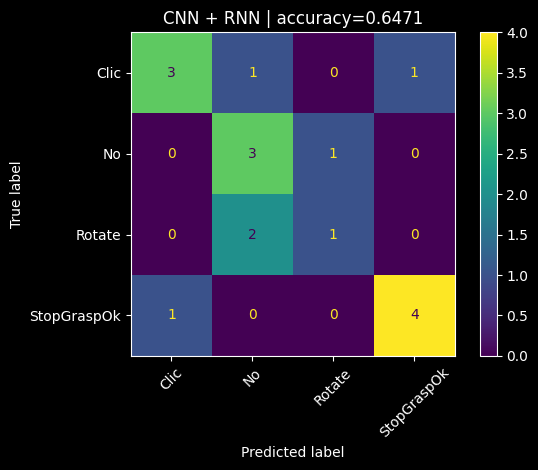

In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
import cv2
import numpy as np


target_len = 30
img_size = 64
cnn_feature_dim = 16
hidden_dim = 16
epochs = 300
lr = 0.005


def sequence_images(sequence_path):
    frame_paths = sorted(Path(sequence_path).glob("*.pnm"), key=get_sequence_number)

    frames = []

    for frame_path in frame_paths:
        frame = cv2.imread(str(frame_path), cv2.IMREAD_GRAYSCALE)
        frame = cv2.resize(frame, (img_size, img_size))
        frame = frame.astype(np.float32) / 255.0
        frames.append(frame)

    old_t = np.linspace(0, 1, len(frames))
    new_t = np.linspace(0, 1, target_len)

    sampled = []

    for t in new_t:
        idx = np.argmin(np.abs(old_t - t))
        sampled.append(frames[idx])

    return np.array(sampled, dtype=np.float32)


def run_cnn_rnn():
    X_train, y_train = [], []
    X_test, y_test = [], []

    for label, gesture in enumerate(gestures):
        sequence_paths = sorted(
            [p for p in (base_path / gesture).iterdir() if p.is_dir()],
            key=get_sequence_number
        )

        for i, sequence_path in enumerate(sequence_paths):
            seq = sequence_images(sequence_path)

            if i < 10:
                X_train.append(seq)
                y_train.append(label)
            else:
                X_test.append(seq)
                y_test.append(label)

    X_train = torch.tensor(np.array(X_train), dtype=torch.float32).unsqueeze(2)
    X_test = torch.tensor(np.array(X_test), dtype=torch.float32).unsqueeze(2)

    y_train = torch.tensor(y_train, dtype=torch.long)
    y_test = torch.tensor(y_test, dtype=torch.long)

    num_classes = len(gestures)

    torch.manual_seed(1)

    cnn = nn.Sequential(
        nn.Conv2d(1, 4, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(4, 8, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.AdaptiveAvgPool2d((4, 4)),

        nn.Flatten(),
        nn.Linear(8 * 4 * 4, cnn_feature_dim),
        nn.ReLU()
    )

    rnn = nn.RNN(
        input_size=cnn_feature_dim,
        hidden_size=hidden_dim,
        batch_first=True
    )

    fc = nn.Linear(hidden_dim, num_classes)

    loss_fn = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        list(cnn.parameters()) + list(rnn.parameters()) + list(fc.parameters()),
        lr=lr
    )

    for epoch in range(epochs):
        n, t, c, h, w = X_train.shape

        cnn_features = cnn(X_train.reshape(n * t, c, h, w))
        cnn_features = cnn_features.reshape(n, t, cnn_feature_dim)

        _, hidden = rnn(cnn_features)
        logits = fc(hidden[-1])

        loss = loss_fn(logits, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        n, t, c, h, w = X_test.shape

        cnn_features = cnn(X_test.reshape(n * t, c, h, w))
        cnn_features = cnn_features.reshape(n, t, cnn_feature_dim)

        _, hidden = rnn(cnn_features)
        logits = fc(hidden[-1])

        probs = torch.softmax(logits, dim=1)
        y_pred = torch.argmax(probs, dim=1)

    acc = (y_pred == y_test).float().mean().item()

    cm = np.zeros((num_classes, num_classes), dtype=int)

    for true_label, pred_label in zip(y_test.numpy(), y_pred.numpy()):
        cm[true_label, pred_label] += 1

    print(f"CNN + RNN | accuracy={acc:.4f}")
    print("Probabilities:")
    print(probs.numpy())

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=gestures
    )

    disp.plot(xticks_rotation=45)
    plt.title(f"CNN + RNN | accuracy={acc:.4f}")
    plt.tight_layout()
    plt.show()

    return probs, y_pred


probs_cnn, pred_cnn = run_cnn_rnn()